# From a question to a verified model

**Source mapping:** Vercauteren, Simulation and Modelling 2 (9 July 2025), §1, pp. 4–6.

Independent study companion; explanations and experiments are newly written. Read in the README order.

## Model and reasoning

Question: how quickly does a temperature anomaly disappear? Assume a well-mixed body and fixed surroundings. With anomaly $y=T-T_a$, Newton cooling gives $y'=-ay$, $y(0)=1$, and $y(t)=e^{-at}$.

State, parameter and boundary assumptions are different: $y$ evolves; $a$ is supplied; the environment is assumed constant. Changing this assumption introduces model error. Uncertain $a$ produces parameter error; replacing the derivative produces discretisation error. Floating-point arithmetic adds roundoff. These errors must not be combined into a single unexplained discrepancy.

A useful workflow is question → assumptions → equation → analytical properties → numerical method → verification against a known solution → validation against independent observations. This notebook performs verification only.

## Reproducible experiment

Predict the plot before running. All parameters below are illustrative, not measured environmental data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

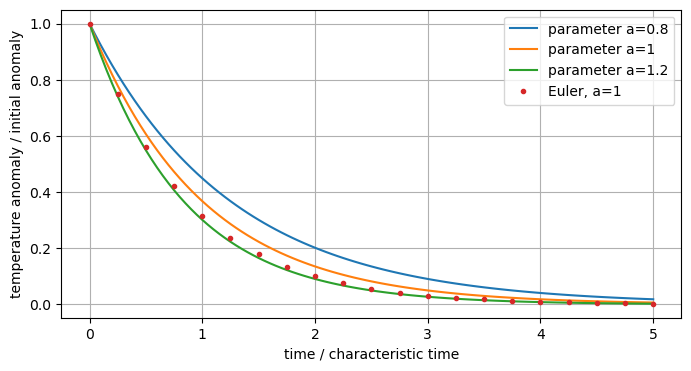

Final-time Euler errors: [np.float64(0.0035667350601514738), np.float64(0.0019480947080573975), np.float64(0.0010139142217520858), np.float64(0.0005167424298548858)]


In [2]:
t=np.linspace(0,5,101); exact=np.exp(-t)
for a in [0.8,1,1.2]: plt.plot(t,np.exp(-a*t),label=f"parameter a={a}")
h=0.25; tn=np.arange(21)*h; y=(1-h)**np.arange(21)
plt.plot(tn,y,"o",ms=3,label="Euler, a=1")
plt.xlabel("time / characteristic time");plt.ylabel("temperature anomaly / initial anomaly");plt.legend();plt.show()
errors=[]
for n in [20,40,80,160]:
 h=5/n; errors.append(abs((1-h)**n-np.exp(-5)))
assert all(np.diff(errors)<0)
print("Final-time Euler errors:",errors)

## Read the result

Refinement reduces discretisation error, but cannot repair an incorrect cooling law or uncertain parameter. Specify whether accuracy, efficiency, convergence or long-time behaviour matters before selecting a method.

## Your turn

Explain how a changing ambient temperature changes the equation. Which additional observations would be needed for validation?

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.